In [2]:
import numpy as np
import matplotlib.pyplot as plt

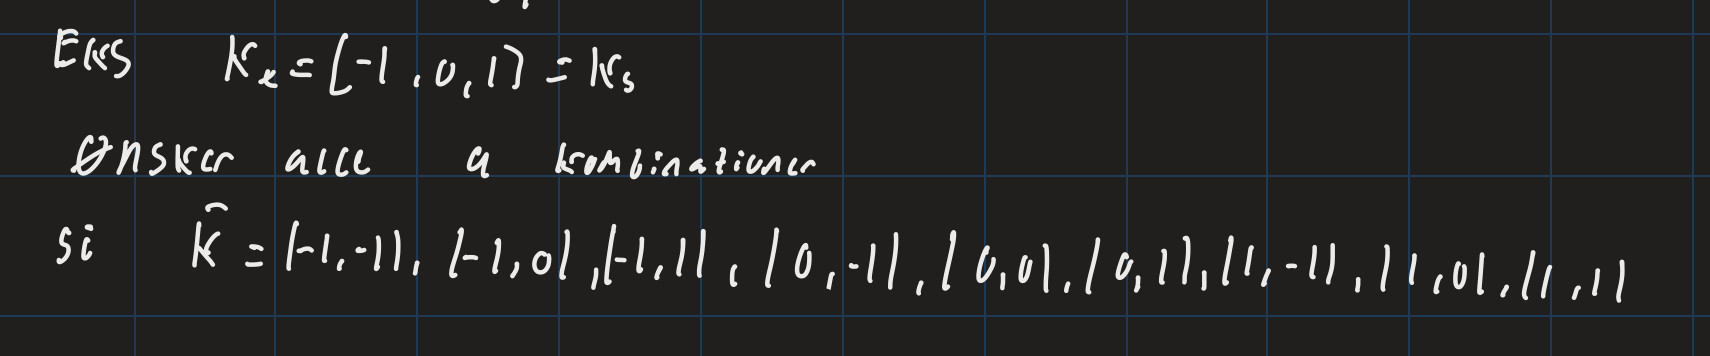
Skal skrive k.

Den laver alle kombinationer af k_x og k_y, og derfor er der 9 punkter i k-rummet.

In [3]:
x=np.array([-1, 0, 1])
y=np.array([-2, 2, 4])
KX, KY = np.meshgrid(x, y, indexing="ij") # laver et 2D gitter af k_x og k_y
print(KX)
print(KY)
#laver 2 arrays et der er x koordinaterne fastholdt søjler og et der er y koordinaterne fastholdt rækker.

[[-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]]
[[-2  2  4]
 [-2  2  4]
 [-2  2  4]]


In [4]:
print(KX.ravel(),KY.ravel()) # Raveling flader 2D arrays til 1D arrays.
K=np.stack([KX.ravel(), KY.ravel()], axis=1)   # (n**2, 2)
print(K) # np.stack sæ¨

[-1 -1 -1  0  0  0  1  1  1] [-2  2  4 -2  2  4 -2  2  4]
[[-1 -2]
 [-1  2]
 [-1  4]
 [ 0 -2]
 [ 0  2]
 [ 0  4]
 [ 1 -2]
 [ 1  2]
 [ 1  4]]


In [5]:
N=1
idx=np.arange((2*N+1)**2)
idx1=idx[:, None] 
idx2=idx[None, :]
print(np.sqrt((idx1-idx2)**2)+(idx1-idx2)**2) # laver et array med afstande mellem alle kombinationer af k_x og k_y


[[ 0.  2.  6. 12. 20. 30. 42. 56. 72.]
 [ 2.  0.  2.  6. 12. 20. 30. 42. 56.]
 [ 6.  2.  0.  2.  6. 12. 20. 30. 42.]
 [12.  6.  2.  0.  2.  6. 12. 20. 30.]
 [20. 12.  6.  2.  0.  2.  6. 12. 20.]
 [30. 20. 12.  6.  2.  0.  2.  6. 12.]
 [42. 30. 20. 12.  6.  2.  0.  2.  6.]
 [56. 42. 30. 20. 12.  6.  2.  0.  2.]
 [72. 56. 42. 30. 20. 12.  6.  2.  0.]]


In [ ]:
def k_2d(k_max, N):
    kx = np.linspace(-k_max, k_max, 2*N+1) # k-rummet der går fra -k_max til k_max med 2*N+1 punkter
    dk = k_max/N # skridtstørrelse
    KX, KY = np.meshgrid(kx, kx, indexing="ij") # laver et 2D gitter af k_x og k_y
    K = np.stack([KX.ravel(), KY.ravel()], axis=1)   # (n**2, 2)
    return K, dk
def kinetic_energy_2d(K):
    return np.diag(0.5 * np.sum(K**2, axis=1))# beregner den kinetiske energi for hver kombination af k_x og k_y
# axis=1 summer over rækkerne, så vi får k_x^2 + k_y^2 for hver kombination af k_x og k_y.
def potential_2d(K, dk, a):
    k_x=k[:,0]
    k_y=k[:,1]
    D=np.sqrt((k_x[:, None]-k_x[None,:])**2+(k_y[:, None]-k_y[None,:])**2)+dk
    return -a*dk/(D*(2*np.pi)**2)

In [40]:
from scipy.linalg import eigh
k_max = 5
N = 40
a=2
k, dk = k_2d(k_max, N)
H=kinetic_energy_2d(k) + potential_2d(k, dk, a)
E, U = eigh(H, subset_by_index=[0, 2]) # beregner egenværdier og egenvektorer for H

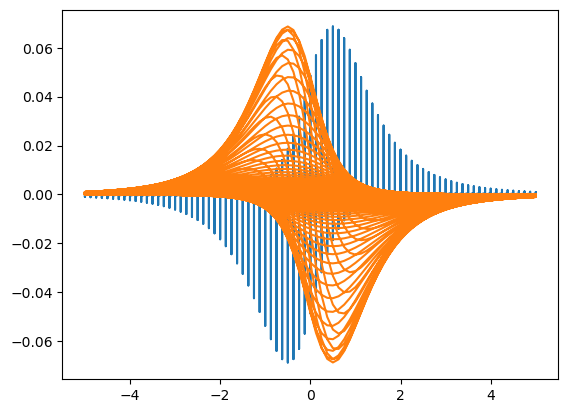

In [41]:
#plt.plot(k,U[:,0 ])
plt.plot(k,U[:,1 ])
plt.show()

In [42]:
E_min = np.min(E)
E_vmin=-np.pi *a**2 /2
print("Minimum eigenvalue E_min:", E_min)
print("Analytical minimum eigenvalue E_vmin:", E_vmin)
print("Difference dk:", dk)

Minimum eigenvalue E_min: -6.508076524053938
Analytical minimum eigenvalue E_vmin: -6.283185307179586
Difference dk: 0.125


Så de to gæt ligger tæt på hinanden, men dk er ret høj så det kan sagtens blive bedre. Til sammenligning var den på 0,067 i 1D. Det er fordi vi har 2 dimensioner, så der er flere punkter i k-rummet, og derfor bliver dk højere.

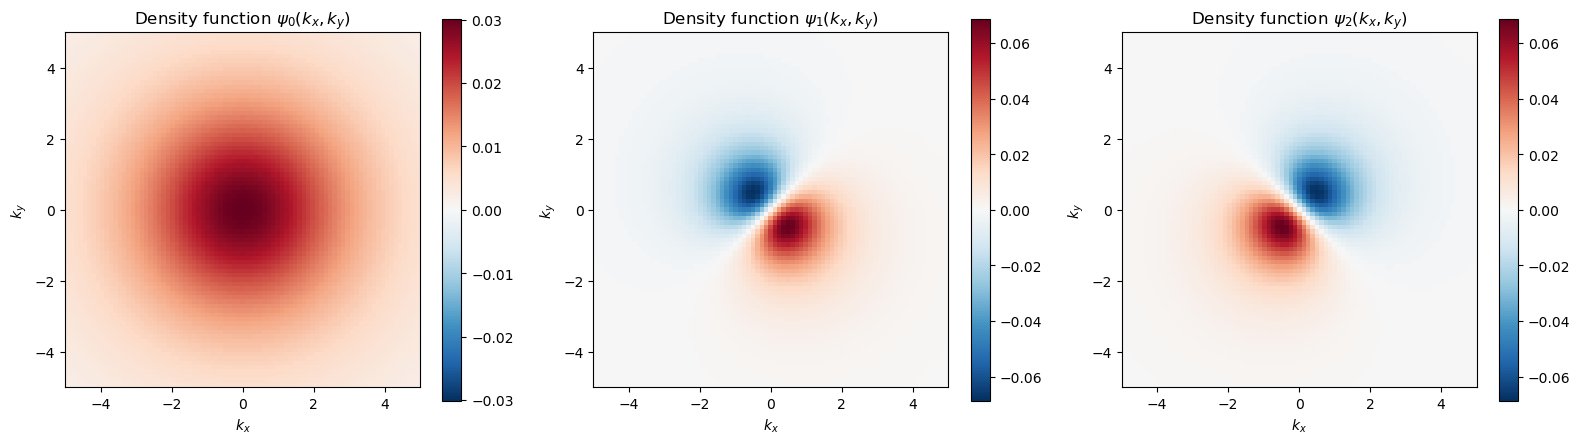

In [43]:
kx = np.linspace(-k_max, k_max, 2*N+1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

for m, axis in zip([0, 1, 2], ax):
    psi = U[:, m].reshape(2*N+1, 2*N+1) # omformer egenvektoren til et 2D array, så vi kan plotte det som et billede
    psi = psi * np.sign(psi.flat[np.argmax(np.abs(psi))])   # fast fortegn
    im = axis.imshow(psi, origin="lower", cmap="RdBu_r",
                     extent=[-k_max, k_max, -k_max, k_max],
                     vmin=-np.abs(psi).max(), vmax=np.abs(psi).max())
    axis.set_title(f"$n={m}$,  $E={E[m]:.2f}$")
    axis.set_xlabel("$k_x$"); axis.set_ylabel("$k_y$")
    title = f"Density function $\\psi_{m}(k_x, k_y)$"
    axis.set_title(title)
    fig.colorbar(im, ax=axis)

fig.tight_layout(); plt.show()

Fourier transformere nu tilbage til x rummet.

In [24]:
len(U[:, 0])

6561

In [ ]:
def xy_2d(x_max, N_x):
    x = np.linspace(-x_max, x_max, 2*N_x+1)
    dx = x_max / N_x
    XX, YY = np.meshgrid(x, x, indexing="ij")
    R = np.stack([XX.ravel(), YY.ravel()], axis=1)
    return R, dx
#Fuldsstændig det samme som i k-rummet nu bare i x y rummet.

(R @ k.T) er matrix multiplikation melem R og k.T T betyder blot den transponeres. så det bliver nk søjler og nx rækker.
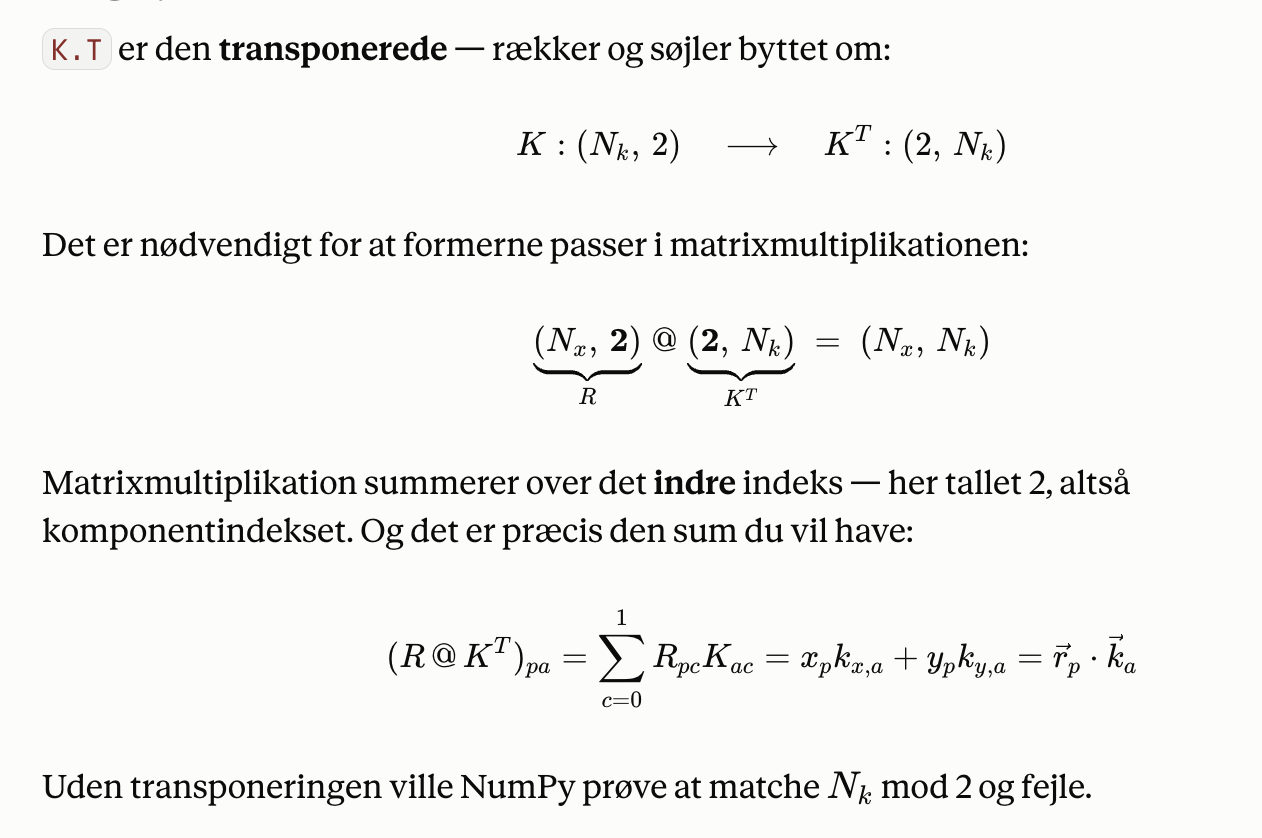

In [104]:
x_max, N_x = 1.8, 40
R, dx = xy_2d(x_max, N_x) 
M = np.exp(1j * (R @ k.T))                       # (nx**2, nk)


In [105]:
psi_x = (dk/(2*np.pi))**2 * (M @ U[:, :3])       # (nx**2, 3)
psi0  = psi_x[:, 0].reshape(N_x, N_x)              # til imshow

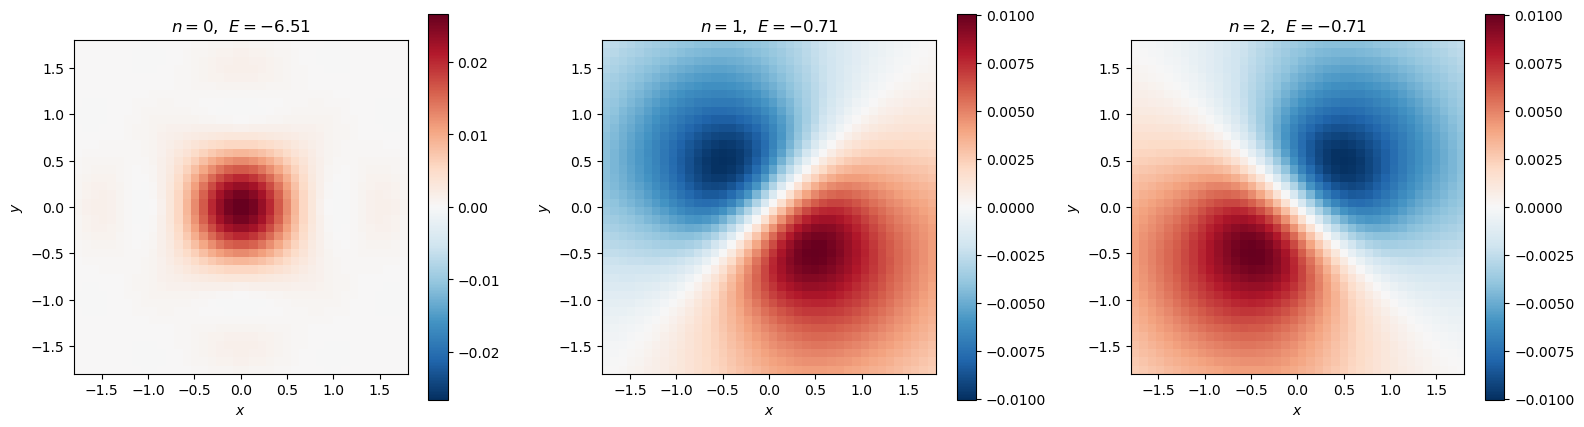

In [106]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

for m, axis in zip([0, 1, 2], ax):
    psi = psi_x[:, m].reshape(N_x, N_x)              # N_x, ikke 2*N+1
    psi = psi * np.exp(-1j*np.angle(psi.flat[np.argmax(np.abs(psi))]))
    psi = psi.real                                 # psi_x er kompleks

    im = axis.imshow(psi, origin="lower", cmap="RdBu_r",
                     extent=[-x_max, x_max, -x_max, x_max],    # x-området, ikke k
                     vmin=-np.abs(psi).max(), vmax=np.abs(psi).max())
    axis.set_title(f"$n={m}$,  $E={E[m]:.2f}$")
    axis.set_xlabel("$x$"); axis.set_ylabel("$y$")
    fig.colorbar(im, ax=axis)

fig.tight_layout(); plt.show()